In [1]:
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import seaborn as sns

from ml3_04_cv_methods_jacquieb import (
    make_group_k_fold_splits,
    make_k_fold_splits,
    make_quantile_stratification_field,
    make_stratified_k_fold_splits,
    make_time_series_splits,
    )
from ml3_03_split_visualization_jacquieb import visualize_k_fold_split

DF_PATH = r'.\data\train_df_processed_full.csv'

df = pd.read_csv(DF_PATH)
df["created"] = pd.to_datetime(df["created"])


## K-Fold

`K-Fold` делит датасет на `k` примерно равных частей. На каждой итерации один фолд используется как `test`, остальные фолды объединяются в `train`.

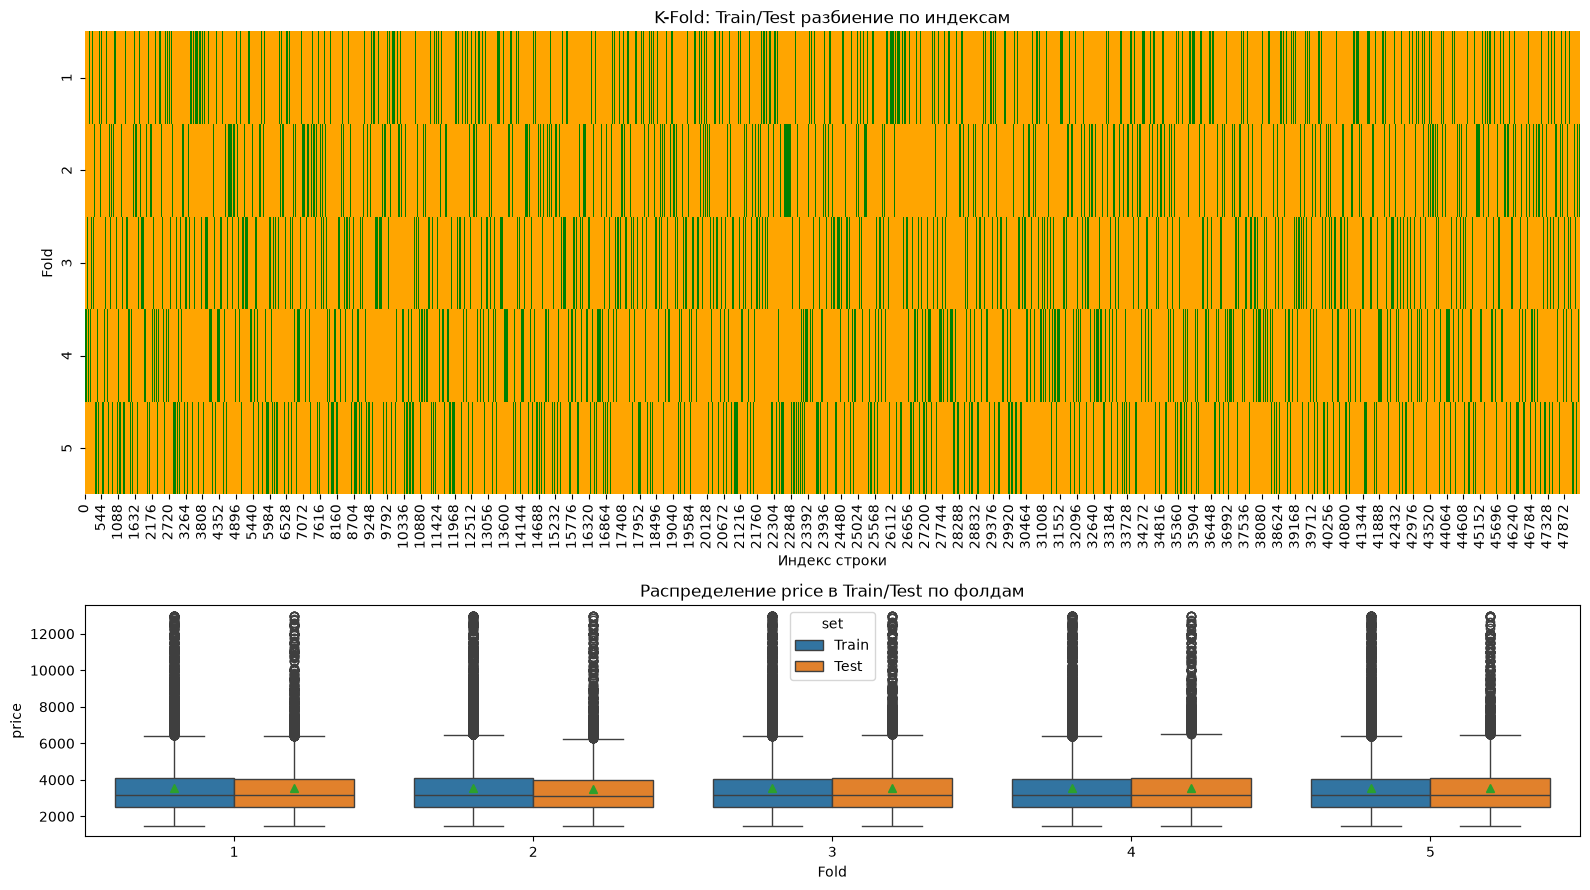

In [2]:
splits = make_k_fold_splits(df, k=5, random_state=21)

visualize_k_fold_split(df, splits)

## Grouped K-Fold

`Grouped K-Fold` нужен, когда объекты одной группы нельзя разделять между `train` и `test` внутри одного фолда.

Для демонстрации используем `bedrooms` как пример.
Важно: group_field — это колонка, по которой нельзя допускать пересечения между train и test. То есть одна и та же группа должна быть либо только в train, либо только в test внутри одного фолда.

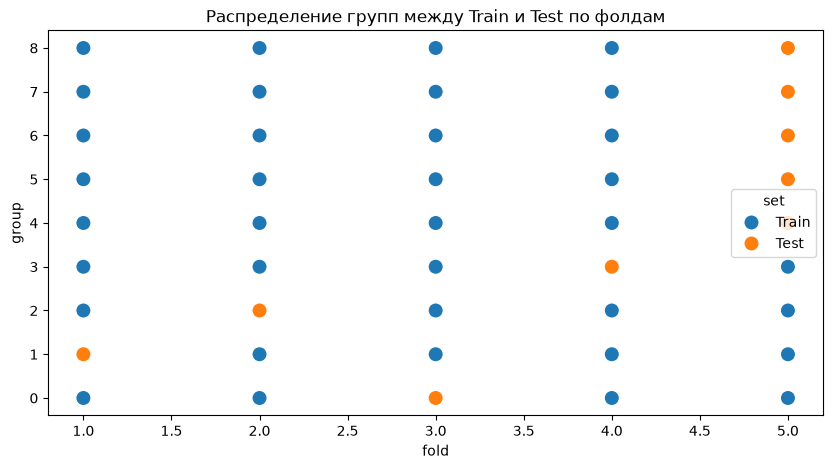

In [3]:
field_name = 'bedrooms'
splits = make_group_k_fold_splits(df, k=5, group_field=field_name)
rows = []

for fold, (train_idx, test_idx) in enumerate(splits, start=1):
    train_groups = set(df.iloc[train_idx][field_name])
    test_groups = set(df.iloc[test_idx][field_name])

    for group in train_groups:
        rows.append({'fold': fold, 'group': group, 'set': 'Train'})

    for group in test_groups:
        rows.append({'fold': fold, 'group': group, 'set': 'Test'})

groups_df = pd.DataFrame(rows)

plt.figure(figsize=(10, 5))
sns.scatterplot(data=groups_df, x='fold', y='group', hue='set', s=120)
plt.title('Распределение групп между Train и Test по фолдам')
plt.show()

##  Stratified K-Fold

`Stratified K-Fold` сохраняет распределение выбранного поля в каждом фолде. Так как целевая переменная - `price`, задача является регрессионной.

Непрерывный `price` нельзя напрямую использовать как `stratify_field`: почти каждое значение может оказаться отдельным классом. Поэтому сначала создаем дискретное поле `price_bin`, разбивая `price` на квантили через `make_quantile_stratification_field`. Затем в `make_stratified_k_fold_splits` передаем именно `price_bin`, чтобы фолды сохраняли похожее распределение ценовых диапазонов.

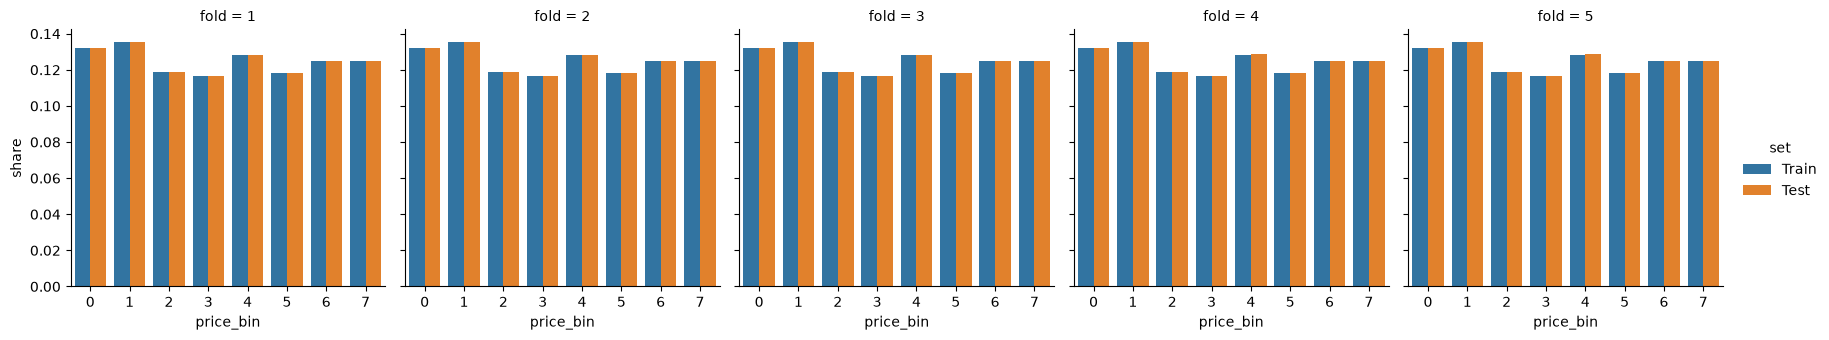

In [4]:
# df["price_bin"] = make_quantile_stratification_field(df, target_field="price", n_bins=5)

df['price_bin'] = make_quantile_stratification_field(df, target_field='price', n_bins=8)

splits = make_stratified_k_fold_splits(df, k=5, stratify_field='price_bin')
rows = []

for fold, (train_idx, test_idx) in enumerate(splits, start=1):
    df_train_fold = df.iloc[train_idx]
    df_test_fold = df.iloc[test_idx]

    for price_bin, share in df_train_fold['price_bin'].value_counts(normalize=True).items():
        rows.append({'fold': fold, 'price_bin': price_bin, 'set': 'Train', 'share': share})

    for price_bin, share in df_test_fold['price_bin'].value_counts(normalize=True).items():
        rows.append({'fold': fold, 'price_bin': price_bin, 'set': 'Test', 'share': share})

vis_df = pd.DataFrame(rows)

sns.catplot(data=vis_df, x='price_bin', y='share', hue='set', col='fold', kind='bar', height=3.5, aspect=1)

plt.show()

## Time series split

`Time series split` используется для данных с временной зависимостью. Данные сортируются по `date_field`; модель обучается на прошлом и проверяется на следующем временном блоке.

Здесь используем поле `created`.

(9676, 25) (9676, 25)


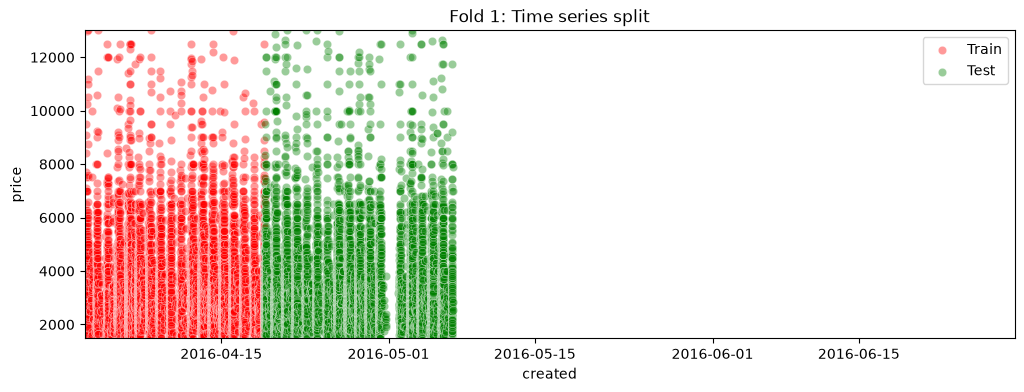

(19352, 25) (9676, 25)


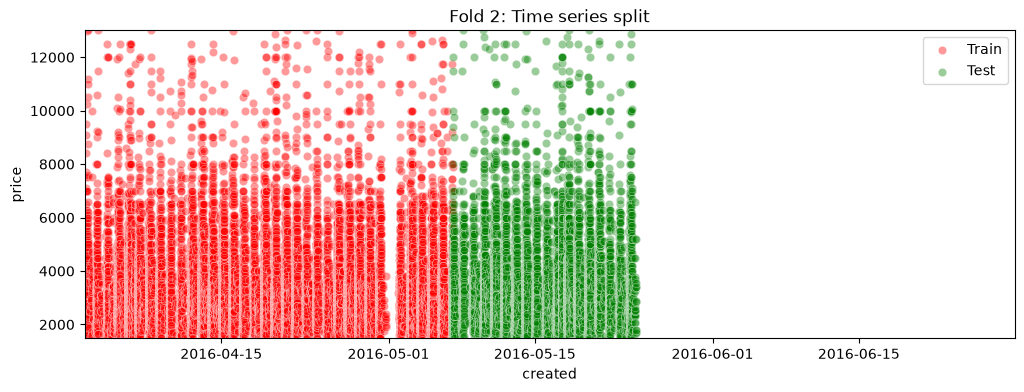

(29028, 25) (9676, 25)


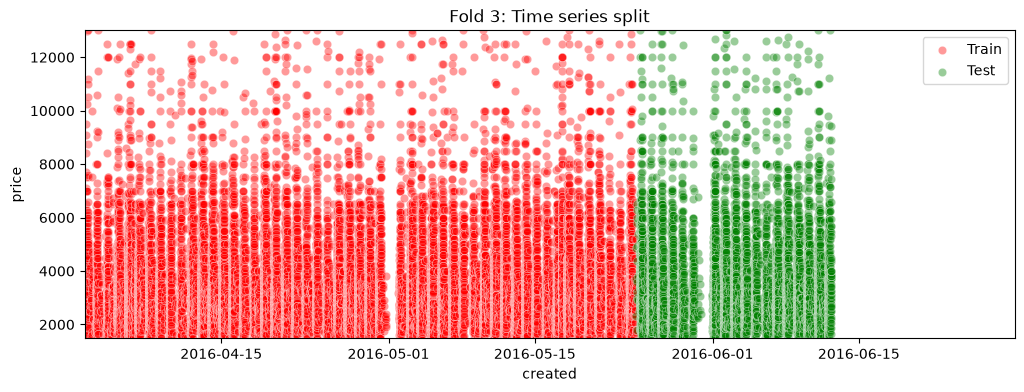

(38704, 25) (9675, 25)


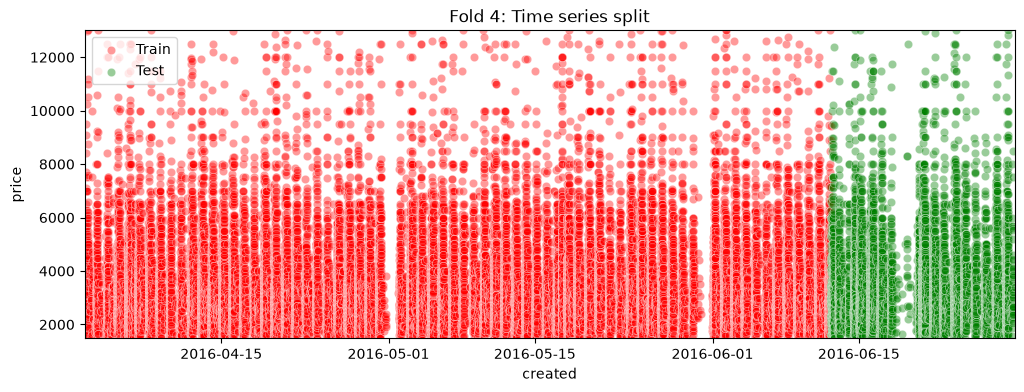

In [5]:
df['created'] = pd.to_datetime(df['created'])

splits = make_time_series_splits(df, k=5, date_field='created')

x_min = df['created'].min()
x_max = df['created'].max()

y_min = df['price'].min()
y_max = df['price'].max()

for fold, (train_idx, test_idx) in enumerate(splits, start=1):
    df_train = df.iloc[train_idx]
    df_test = df.iloc[test_idx]
    print(df_train.shape, df_test.shape)

    plt.figure(figsize=(12, 4))
    sns.scatterplot(data=df_train, x='created', y='price', color='red', alpha=0.4, label='Train')
    sns.scatterplot(data=df_test, x='created', y='price', color='green', alpha=0.4, label='Test')
    plt.xlim(x_min, x_max)
    plt.ylim(y_min, y_max)
    plt.title(f'Fold {fold}: Time series split')
    plt.show()